# MobileNetV2 en Colab — PlantVillage (datos reales, transfer learning)

Notebook autocontenido para Google Colab. **No depende del paquete instalado ni de archivos locales del proyecto**: incluye la descarga del dataset, la configuración (`settings.py`), la carga de datos (`data.py`) y el entrenamiento con MobileNetV2 pre-entrenado (`mobilenet.py`).

Sigue la guía de TensorFlow: https://www.tensorflow.org/tutorials/images/transfer_learning

Runtime recomendado: **GPU** (Runtime → Cambiar tipo de runtime → GPU).


In [1]:
# 0. Instalar dependencias
!pip -q install tensorflow mlflow codecarbon


In [2]:
# 1. Descargar el dataset real de PlantVillage (script de descarga del proyecto)
import os, shutil, subprocess
from pathlib import Path

WORK = Path("/content/leafthealthvision")
DATA_DIR = WORK / "data" / "plantvillage"
REPO_URL = "https://github.com/spMohanty/PlantVillage-Dataset.git"

if not DATA_DIR.exists():
    WORK.mkdir(parents=True, exist_ok=True)
    print(f"Clonando {REPO_URL} ...")
    subprocess.run(
        ["git", "clone", "--depth", "1", REPO_URL, str(DATA_DIR)],
        check=True,
    )
    # Quitar .git anidado
    git_dir = DATA_DIR / ".git"
    if git_dir.exists():
        shutil.rmtree(git_dir)
    # Conservar solo lo necesario: raw/color y metadata
    for item in DATA_DIR.iterdir():
        if item.name not in {
            "raw",
            "leaf_grouping",
            "leaf-map.json",
            "README.md",
            "CITATION.cff",
        }:
            if item.is_dir():
                shutil.rmtree(item)
            else:
                item.unlink()
    print("Dataset listo en:", DATA_DIR)
else:
    print("Dataset ya descargado en:", DATA_DIR)

data_dir = DATA_DIR / "raw" / "color"
print("Imágenes en:", data_dir)
print("Clases encontradas:", len([p for p in data_dir.iterdir() if p.is_dir()]))


Clonando https://github.com/spMohanty/PlantVillage-Dataset.git ...
Dataset listo en: /content/leafthealthvision/data/plantvillage
Imágenes en: /content/leafthealthvision/data/plantvillage/raw/color
Clases encontradas: 38


In [3]:
# 2. Configuración (equivalente a src/leafthealthvision/config/settings.py)
import tensorflow as tf

# Configurar GPU ANTES de cualquier otra operación de TensorFlow
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        # Mixed precision: más rápido en Tensor Cores y menos VRAM
        tf.keras.mixed_precision.set_global_policy("mixed_float16")
        print(f"GPU activada: {len(gpus)} dispositivo(s), mixed_float16")
    except RuntimeError as e:
        print(f"Nota GPU (ya inicializada): {e}")
else:
    print("No se detectó GPU; se usará CPU")

import matplotlib.pyplot as plt
import numpy as np
from tensorflow import keras
from tensorflow.keras import applications, layers, models
from tensorflow.keras.layers import Input
from tensorflow.keras.models import Model

SEED = 42
BATCH_SIZE = 620
IMAGE_TARGET_SIZE = (224, 224)
IMAGE_RESCALE = 1.0 / 255.0
OPTIMIZER = "adam"
METRICS = ["accuracy"]
EARLY_STOPPING_PATIENCE = 5
TRAIN_SPLIT = 0.8
VAL_SPLIT = 0.1
EPOCHS = 10

tf.random.set_seed(SEED)
np.random.seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE

print("Config cargada. Imagen objetivo:", IMAGE_TARGET_SIZE, "| Batch:", BATCH_SIZE)


GPU activada: 1 dispositivo(s), mixed_float16
Config cargada. Imagen objetivo: (224, 224) | Batch: 620


In [4]:
# MLflow: seguimiento del experimento (se guarda en ./mlruns del entorno)
import mlflow
import mlflow.tensorflow
from codecarbon import EmissionsTracker

mlflow.set_tracking_uri("sqlite:///mlflow.db")
mlflow.set_experiment("leafthealthvision")


class MlflowEpochLogger(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        mlflow.log_metrics({k: float(v) for k, v in logs.items()}, step=epoch)


2026/11/17 02:37:53 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/17 02:37:53 INFO mlflow.store.db.utils: Updating database tables
2026/11/17 02:37:55 INFO mlflow.tracking.fluent: Experiment with name 'leafthealthvision' does not exist. Creating a new experiment.


In [5]:
# 3. Cargar datasets (equivalente a src/leafthealthvision/data.py, adaptado a Colab)
def load_datasets(
    data_dir, batch_size, img_size, seed, train_split=TRAIN_SPLIT, val_split=VAL_SPLIT
):
    full_dataset = tf.keras.utils.image_dataset_from_directory(
        data_dir,
        label_mode="int",
        image_size=img_size,
        batch_size=batch_size,
        seed=seed,
    )
    class_names = full_dataset.class_names
    # Sin .cache() (evita cargar ~100 GB en RAM) y shuffle buffer pequeño
    full_dataset = full_dataset.shuffle(
        buffer_size=32, seed=seed, reshuffle_each_iteration=False
    )

    n_batches = int(full_dataset.cardinality().numpy())
    n_train = int(n_batches * train_split)
    n_val = int(n_batches * val_split)

    train_dataset = full_dataset.take(n_train)
    rest = full_dataset.skip(n_train)
    validation_dataset = rest.take(n_val)
    test_dataset = rest.skip(n_val)

    train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
    validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
    test_dataset = test_dataset.prefetch(buffer_size=AUTOTUNE)

    return train_dataset, validation_dataset, test_dataset, class_names


train_ds, validation_ds, test_ds, class_names = load_datasets(
    data_dir=data_dir,
    batch_size=BATCH_SIZE,
    img_size=IMAGE_TARGET_SIZE,
    seed=SEED,
)

print("Clases:", len(class_names))
print("Train batches:", train_ds.cardinality().numpy())
print("Val batches:", validation_ds.cardinality().numpy())
print("Test batches:", test_ds.cardinality().numpy())


Found 54305 files belonging to 38 classes.
Clases: 38
Train batches: 70
Val batches: 8
Test batches: 10


In [6]:
# 4. Modelo con transfer learning MobileNetV2 (equivalente a src/leafthealthvision/training/mobilenet.py)
img_height, img_width = IMAGE_TARGET_SIZE
num_classes = len(class_names)

# Base pre-entrenada de MobileNetV2 sin la cabeza (include_top=False)
base_model = applications.MobileNetV2(
    input_shape=(img_height, img_width, 3),
    include_top=False,
    weights="imagenet",
)

# Congelar la base: solo se entrena la cabeza nueva
base_model.trainable = False

inputs = Input(shape=(img_height, img_width, 3))
x = layers.Rescaling(IMAGE_RESCALE)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(num_classes)(x)
model = Model(inputs, outputs)

model.compile(
    optimizer=OPTIMIZER,
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=METRICS,
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [7]:
# 5. Entrenar con EarlyStopping (con MLflow y huella de carbono)
early_stop = tf.keras.callbacks.EarlyStopping(
    patience=EARLY_STOPPING_PATIENCE, restore_best_weights=True
)

tracker = EmissionsTracker(save_to_file=False)

with mlflow.start_run(run_name="mobilenetv2_transfer_learning"):
    mlflow.log_params(
        {
            "model": "mobilenetv2",
            "base_model_weights": "imagenet",
            "base_trainable": False,
            "epochs": EPOCHS,
            "batch_size": BATCH_SIZE,
            "img_height": img_height,
            "img_width": img_width,
            "image_rescale": IMAGE_RESCALE,
            "optimizer": OPTIMIZER,
            "loss": "SparseCategoricalCrossentropy(from_logits=True)",
            "metrics": ",".join(METRICS),
            "early_stopping_patience": EARLY_STOPPING_PATIENCE,
            "num_classes": len(class_names),
        }
    )

tracker.start()
history = model.fit(
    train_ds,
    validation_data=validation_ds,
    epochs=EPOCHS,
    callbacks=[early_stop, MlflowEpochLogger()],
)

emisiones_kg = tracker.stop() or 0.0
energia_kwh = getattr(getattr(tracker, "_total_energy", None), "kWh", None)

acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]

final_metrics = {
    "final_accuracy": float(acc[-1]),
    "final_val_accuracy": float(val_acc[-1]),
    "final_loss": float(loss[-1]),
    "final_val_loss": float(val_loss[-1]),
    "carbon_emissions_kg": float(emisiones_kg),
}
if energia_kwh is not None:
    final_metrics["energy_consumed_kwh"] = float(energia_kwh)
mlflow.log_metrics(final_metrics)

try:
    mlflow.tensorflow.log_model(model, name="model")
except Exception as exc:
    print(f"No se pudo registrar el modelo en MLflow: {exc}")

print(f"Huella de carbono del entrenamiento: {emisiones_kg:.6f} kg CO2eq")


[codecarbon WARNING @ 02:38:07] Multiple instances of codecarbon are allowed to run at the same time.
[codecarbon INFO @ 02:38:07] [setup] RAM Tracking...
[codecarbon INFO @ 02:38:07] [setup] CPU Tracking...
[codecarbon INFO @ 02:38:07] [setup] GPU Tracking...
[codecarbon INFO @ 02:38:07] Tracking Nvidia GPUs via PyNVML
[codecarbon WARNING @ 02:38:08] We saw that you have a Intel(R) Xeon(R) CPU @ 2.00GHz but we don't know it. Please help us add it, see https://docs.codecarbon.io/latest/how-to/troubleshooting/#unknown-cpu-model
[codecarbon WARNING @ 02:38:08] We will use the default power consumption of 4 W per thread for your 8 CPU, so 32W.
[codecarbon WARNING @ 02:38:08] No CPU tracking mode found. Falling back on estimation based on TDP for CPU. 
 Linux OS detected: Please ensure RAPL files exist, and are readable, at /sys/class/powercap/intel-rapl/subsystem to measure CPU

[codecarbon INFO @ 02:38:08] CPU Model on constant consumption mode: Intel(R) Xeon(R) CPU @ 2.00GHz
[codecarbon

Epoch 1/10


[codecarbon INFO @ 02:38:23] Energy consumed for RAM : 0.000083 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 02:38:23] Energy consumed for all GPUs : 0.000109 kWh. Total GPU Power : 26.13503106007551 W
[codecarbon INFO @ 02:38:23] Delta energy consumed for CPU with cpu_load : 0.000020 kWh, power : 4.735985030052401 W
[codecarbon INFO @ 02:38:23] Energy consumed for All CPU : 0.000020 kWh
[codecarbon INFO @ 02:38:23] 0.000212 kWh of electricity and 0.000000 L of water were used since the beginning.
[codecarbon INFO @ 02:38:38] Energy consumed for RAM : 0.000167 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 02:38:38] Energy consumed for all GPUs : 0.000329 kWh. Total GPU Power : 52.76204159880516 W
[codecarbon INFO @ 02:38:38] Delta energy consumed for CPU with cpu_load : 0.000022 kWh, power : 5.1858616297947995 W
[codecarbon INFO @ 02:38:38] Energy consumed for All CPU : 0.000041 kWh
[codecarbon INFO @ 02:38:38] 0.000537 kWh of electricity and 0.000000 L of water were used since the beginnin

65/70 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - accuracy: 0.4597 - loss: 2.1906

[codecarbon INFO @ 02:39:23] Energy consumed for RAM : 0.000416 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 02:39:23] Energy consumed for all GPUs : 0.001112 kWh. Total GPU Power : 59.20258027389567 W
[codecarbon INFO @ 02:39:23] Delta energy consumed for CPU with cpu_load : 0.000033 kWh, power : 7.848475221926561 W
[codecarbon INFO @ 02:39:23] Energy consumed for All CPU : 0.000102 kWh
[codecarbon INFO @ 02:39:23] 0.001630 kWh of electricity and 0.000000 L of water were used since the beginning.


70/70 ━━━━━━━━━━━━━━━━━━━━ 0s 192ms/step - accuracy: 0.4761 - loss: 2.1289

... (40 outputs left out)

[codecarbon INFO @ 02:44:38] Energy consumed for RAM : 0.002165 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 02:44:38] Energy consumed for all GPUs : 0.005192 kWh. Total GPU Power : 38.34589199625558 W
[codecarbon INFO @ 02:44:38] Delta energy consumed for CPU with cpu_load : 0.000062 kWh, power : 14.92256034910247 W
[codecarbon INFO @ 02:44:38] Energy consumed for All CPU : 0.001267 kWh
[codecarbon INFO @ 02:44:38] 0.008625 kWh of electricity and 0.000000 L of water were used since the beginning.


70/70 ━━━━━━━━━━━━━━━━━━━━ 33s 407ms/step - accuracy: 0.9665 - loss: 0.1298 - val_accuracy: 0.9611 - val_loss: 0.1385


[codecarbon INFO @ 02:44:40] Energy consumed for RAM : 0.002178 kWh. RAM Power : 20.0 W
[codecarbon INFO @ 02:44:40] Energy consumed for all GPUs : 0.005228 kWh. Total GPU Power : 54.83383033858192 W
[codecarbon INFO @ 02:44:40] Delta energy consumed for CPU with cpu_load : 0.000003 kWh, power : 5.11525848942015 W
[codecarbon INFO @ 02:44:40] Energy consumed for All CPU : 0.001271 kWh
[codecarbon INFO @ 02:44:40] 0.008677 kWh of electricity and 0.000000 L of water were used since the beginning.
[codecarbon WARNING @ 02:44:41] Unable to access geographical location through primary API. Will resort to using the backup API - Exception : Region is empty - url=https://get.geojs.io/v1/ip/geo.json
2026/11/17 02:44:41 WARNING mlflow.tensorflow: You are saving a TensorFlow Core model or Keras model without a signature. Inference with mlflow.pyfunc.spark_udf() will not work unless the model's pyfunc representation accepts pandas DataFrames as inference inputs.


Huella de carbono del entrenamiento: 0.004085 kg CO2eq


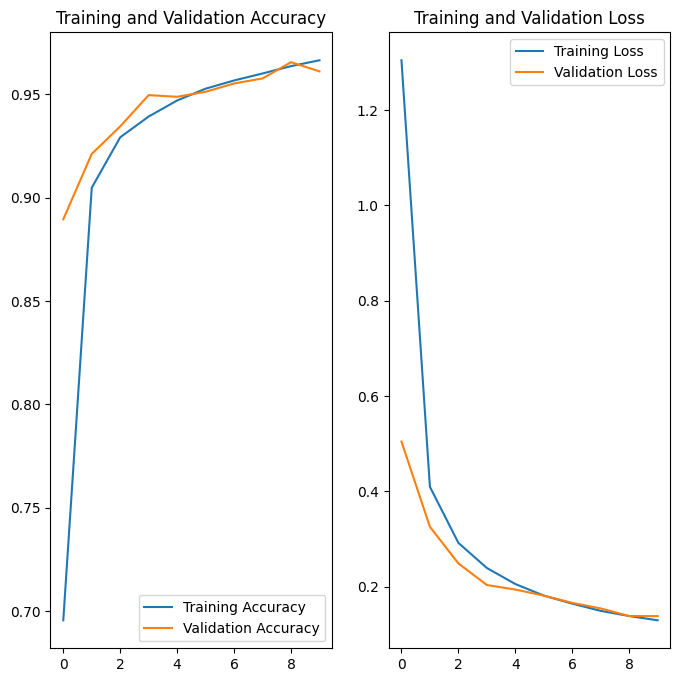

In [8]:
# 6. Graficar accuracy y loss
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(len(acc))

plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Training Accuracy")
plt.plot(epochs_range, val_acc, label="Validation Accuracy")
plt.legend(loc="lower right")
plt.title("Training and Validation Accuracy")

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Training Loss")
plt.plot(epochs_range, val_loss, label="Validation Loss")
plt.legend(loc="upper right")
plt.title("Training and Validation Loss")
plt.show()


In [9]:
!curl https://static.vecteezy.com/system/resources/previews/011/855/781/non_2x/green-leaf-of-apple-tree-photo.jpg --output test.jpg

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  100k  100  100k    0     0  1880k      0 --:--:-- --:--:-- --:--:-- 1927k


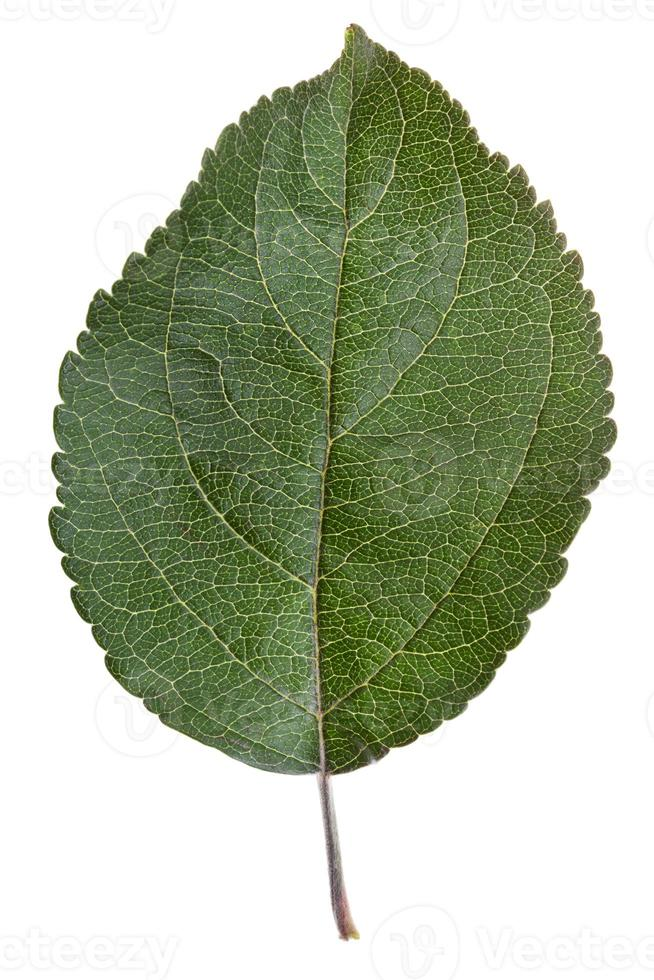

In [10]:
from PIL import Image
from IPython.display import display

imagen = Image.open("/content/test.jpg")
display(imagen)

In [12]:
img = tf.keras.utils.load_img("/content/test.jpg", target_size=(img_height, img_width))
img_array = tf.keras.utils.img_to_array(img)
img_array = tf.expand_dims(img_array, 0)  # Create a batch

predictions = model.predict(img_array)
score = tf.nn.softmax(predictions[0])

print(
    f"This image most likely belongs to {class_names[np.argmax(score)]} with a {100 * np.max(score):.2f} percent confidence."
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
This image most likely belongs to Apple___healthy with a 96.94 percent confidence.
